# 🎨 Proyecto Final Guiado: Análisis Perceptual y Limpieza de Datos en el Espacio de Color
### Introducción a Python para Ciencia de Datos e Inteligencia Artificial
---

## 🎯 Contexto del Proyecto

En este proyecto final trabajarás con los datos reales recopilados a través de la plataforma web del juego de mesa **Hues and Cues**, publicado en la investigación científica sobre percepción cromática humana e Inteligencia Artificial (*Alabau-Bosque et al.*).

En el juego, los participantes ven una palabra (por ejemplo: `"MANZANA"`, `"FLAMENCO"`, `"ESPERANZA"`, `"TRACTOR"`) y deben seleccionar una casilla del tablero (una cuadrícula de 480 tonos de color con coordenadas de la `A1` a la `P30`) que mejor represente el concepto visual de dicha palabra.

### 🎯 Objetivos de Aprendizaje:
1. **Manejo de Colecciones y Mapeos:** Uso intensivo de **diccionarios** (`dict`) para traducción de categorías y mapeo de casillas del tablero a nombres cromáticos (`.map()`).
2. **Creación de Funciones Modulares:** Definición de funciones reutilizables con parámetros, retorno y documentación (`def`, `return`, *docstrings*).
3. **Análisis Demográfico y Limpieza de Datos con Pandas:** Exploración de datos, cálculo de frecuencias relativas y filtrado estricto de participantes con **Daltonismo (Deficiencia de Visión Cromática - CVD)** siguiendo la metodología de calidad del artículo científico (Secciones 2.2 y 2.3 de `HuesAndCues.pdf`).
4. **Análisis de Percepción e Hipótesis Culturales:** Estudio comparativo de discrepancias cromáticas en personas daltónicas frente a tricrómatas, y evaluación del fenómeno de las **"anclas culturales"** (*TRACTOR* y *ESPERANZA*).
5. **Visualización de Datos con Seaborn y Matplotlib:** Creación de dashboards demográficos multivariable (`plt.subplots`), gráficos categóricos de barras (`sns.countplot`, `sns.barplot`) y gráficos de consenso ordenados.

## ⚙️ Fase 0: Configuración del Entorno y Librerías

Importaremos las librerías fundamentales de análisis de datos y visualización:
- `pandas` (`pd`): Manipulación tabular y operaciones sobre DataFrames.
- `numpy` (`np`): Soporte numérico y operaciones vectorizadas.
- `matplotlib.pyplot` (`plt`) y `seaborn` (`sns`): Creación de gráficos estadísticos y estéticos.

In [2]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética global
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Librerías importadas y entorno configurado correctamente.")

✅ Librerías importadas y entorno configurado correctamente.


---
## 📥 Fase 1: Ingesta, Exploración y Diccionarios (EDA)

### 1.1 Carga de los Archivos de Datos
Debes cargar dos archivos fundamentales ubicados en el directorio del proyecto:
1. `HC.csv`: Contiene las 3.899 respuestas de los participantes humanos. Cárgalo en un DataFrame llamado `df_humanos`.
2. `board_color_categories.txt`: Mapea cada una de las 480 casillas del tablero a su color semántico básico (`brown`, `red`, `orange`, `yellow`, `green`, `blue`, `purple`, `pink`). Cárgalo en un DataFrame llamado `df_tablero`.

> 💡 **Pistas:**
> - El archivo `board_color_categories.txt` está separado por comas `,` y **no contiene cabecera**. Utiliza `header=None` y asigna nombres a las columnas: `names=['coordinate', 'color']`.
> - Revisa las dimensiones (`.shape`) y las primeras filas (`.head()`) de cada DataFrame.

In [4]:
# TODO 1.1: Cargar los dos archivos de datos
import os

# Rutas relativas compatibles con la ejecución desde T1_1 o desde la raíz
ruta_hc = 'HC.csv' if os.path.exists('HC.csv') else 'T1_1/HC.csv'
ruta_tablero = 'board_color_categories.txt' if os.path.exists('board_color_categories.txt') else 'T1_1/board_color_categories.txt'

# 1. Cargar las respuestas de los participantes humanos
df_humanos = pd.read_csv(ruta_hc)

# 2. Cargar el mapeo de casillas del tablero a colores básicos (sin cabecera)
df_tablero = pd.read_csv(ruta_tablero, header=None, names=['coordinate', 'color'])

# Mostrar dimensiones y primeras filas
print(f"Dimensiones de df_humanos : {df_humanos.shape[0]} respuestas x {df_humanos.shape[1]} columnas")
print(f"Dimensiones de df_tablero : {df_tablero.shape[0]} casillas x {df_tablero.shape[1]} columnas\n")

print('--- Primeras 5 filas de df_humanos ---')
display(df_humanos.head())

print('--- Primeras 5 filas de df_tablero ---')
display(df_tablero.head())


Dimensiones de df_humanos : 3899 respuestas x 10 columnas
Dimensiones de df_tablero : 480 casillas x 2 columnas

--- Primeras 5 filas de df_humanos ---
                                 userId                 timestamp clueCategory  clueId      word coordinate language  gender ageRange colorblind
0  4ae551a8-0d2b-4b34-ab64-8e6721cbe470  2025-07-15T17:14:02.825Z       ANIMAL       1    SALMÓN        E11  spanish  female    20-29         no
1  4ae551a8-0d2b-4b34-ab64-8e6721cbe470  2025-07-15T17:14:41.330Z       ANIMAL       2   BALLENA        K26  spanish  female    20-29         no
2  4ae551a8-0d2b-4b34-ab64-8e6721cbe470  2025-07-15T17:14:48.713Z       ANIMAL       3     PARDO         C2  spanish  female    20-29         no
3  4ae551a8-0d2b-4b34-ab64-8e6721cbe470  2025-07-15T17:15:21.721Z       ANIMAL       4  FLAMENCO        C15  spanish  female    20-29         no
4  4ae551a8-0d2b-4b34-ab64-8e6721cbe470  2025-07-15T17:15:31.790Z       ANIMAL       5     ZORRO         C7  spanish  femal

### 1.2 Inspección de Tipos de Datos y Valores Faltantes
Comprueba si existen valores nulos en `df_humanos` con `.isnull().sum()` y muestra el resumen de columnas y tipos de datos con `.info()`.

In [6]:
# TODO 1.2: Inspeccionar tipos de datos y valores nulos en df_humanos

print('=== 1. Conteo de valores nulos o faltantes por columna ===')
conteo_nulos = df_humanos.isnull().sum()
print(conteo_nulos)

print('\n=== 2. Resumen de columnas, tipos de datos y memoria (info) ===')
df_humanos.info()

print(f"\n¿Existen valores faltantes en el dataset?: {'Sí' if conteo_nulos.sum() > 0 else 'No, el dataset está 100% completo y limpio.'}")


=== 1. Conteo de valores nulos o faltantes por columna ===
userId          0
timestamp       0
clueCategory    0
clueId          0
word            0
coordinate      0
language        0
gender          0
ageRange        0
colorblind      0
dtype: int64

=== 2. Resumen de columnas, tipos de datos y memoria (info) ===
<class 'pandas.DataFrame'>
RangeIndex: 3899 entries, 0 to 3898
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   userId        3899 non-null   str  
 1   timestamp     3899 non-null   str  
 2   clueCategory  3899 non-null   str  
 3   clueId        3899 non-null   int64
 4   word          3899 non-null   str  
 5   coordinate    3899 non-null   str  
 6   language      3899 non-null   str  
 7   gender        3899 non-null   str  
 8   ageRange      3899 non-null   str  
 9   colorblind    3899 non-null   str  
dtypes: int64(1), str(9)
memory usage: 304.7 KB

¿Existen valores faltantes en el dataset?: No,

### 1.3 Normalización de Categorías Semánticas con Diccionarios
Observa los valores únicos en `df_humanos['clueCategory']`. En el dataset original conviven etiquetas en inglés (`FOOD`, `STONE`, `ENVIRONMENT`, `SUBJETIVE`, `PLANT`) y en español (`COMESTIBLE`, `PIEDRA`, `ENTORNO`, `SUBJETIVO`, `PLANTA`).

1. Define un diccionario en Python llamado `traduccion_cat` que traduzca las etiquetas en inglés a su equivalente estándar en español:
   - `'FOOD'` $\rightarrow$ `'COMESTIBLE'`
   - `'STONE'` $\rightarrow$ `'PIEDRA'`
   - `'ENVIRONMENT'` $\rightarrow$ `'ENTORNO'`
   - `'SUBJETIVE'` $\rightarrow$ `'SUBJETIVO'`
   - `'PLANT'` $\rightarrow$ `'PLANTA'`
2. Aplica este diccionario a la columna `df_humanos['clueCategory']` usando el método `.replace(traduccion_cat)`.
3. Muestra el recuento final de cada categoría con `.value_counts()`.

In [8]:
# TODO 1.3: Crear el diccionario de traducción y normalizar df_humanos['clueCategory']

# 1. Definir diccionario de traducción inglés -> español
traduccion_cat = {
    'FOOD': 'COMESTIBLE',
    'STONE': 'PIEDRA',
    'ENVIRONMENT': 'ENTORNO',
    'SUBJETIVE': 'SUBJETIVO',
    'PLANT': 'PLANTA'
}

# 2. Normalizar las categorías usando .replace()
df_humanos['clueCategory'] = df_humanos['clueCategory'].replace(traduccion_cat)

# 3. Mostrar el recuento final de cada categoría normalizada
print('=== Recuento de respuestas por Categoría Semántica Normalizada ===')
conteo_cat = df_humanos['clueCategory'].value_counts()
print(conteo_cat)

print(f"\nTotal de categorías únicas consolidadas: {df_humanos['clueCategory'].nunique()} (todas en español)")


=== Recuento de respuestas por Categoría Semántica Normalizada ===
clueCategory
SUBJETIVO     567
POP           567
ENTORNO       566
COMESTIBLE    562
ANIMAL        549
PIEDRA        547
PLANTA        541
Name: count, dtype: int64

Total de categorías únicas consolidadas: 7 (todas en español)


### 1.4 Mapeo de Casilla a Color Semántico mediante Diccionarios
Para poder analizar qué color eligió cada participante (por ejemplo, si eligió un tono `pink`, `green`, `blue`, etc.), debemos enriquecer `df_humanos` con la información del tablero.

1. Crea un diccionario rápido `coord_a_color` a partir de `df_tablero` combinando las columnas `'coordinate'` y `'color'` usando `dict(zip(...))`.
2. Crea una nueva columna en `df_humanos` llamada `'color'` mapeando la columna `'coordinate'` con el diccionario creado (`df_humanos['coordinate'].map(coord_a_color)`).
3. Muestra las primeras 5 filas con las columnas `['clueId', 'word', 'clueCategory', 'coordinate', 'color']`.

In [10]:
# TODO 1.4: Crear el diccionario coord_a_color y enriquecer df_humanos

# 1. Crear el diccionario coordinate -> color usando dict(zip(...))
coord_a_color = dict(zip(df_tablero['coordinate'], df_tablero['color']))

# 2. Mapear cada casilla elegida en df_humanos a su color semántico del tablero
df_humanos['color'] = df_humanos['coordinate'].map(coord_a_color)

# 3. Mostrar las primeras 5 filas con las columnas solicitadas
columnas_vista = ['clueId', 'word', 'clueCategory', 'coordinate', 'color']
print('=== Primeras 5 filas enriquecidas con la columna \'color\' ===')
display(df_humanos[columnas_vista].head())

# Verificación de integridad: comprobar que no hay casillas sin color mapeado
print(f"Valores nulos en nueva columna 'color': {df_humanos['color'].isnull().sum()}")


=== Primeras 5 filas enriquecidas con la columna 'color' ===
   clueId      word clueCategory coordinate  color
0       1    SALMÓN       ANIMAL        E11   pink
1       2   BALLENA       ANIMAL        K26   blue
2       3     PARDO       ANIMAL         C2  brown
3       4  FLAMENCO       ANIMAL        C15   pink
4       5     ZORRO       ANIMAL         C7    red
Valores nulos en nueva columna 'color': 0


---
## 👥 Fase 2: Perfil Demográfico y Filtrado de Participantes
> *Basado en las Secciones 2.2 y 2.3 del artículo científico (HuesAndCues.pdf)*

### 2.1 Análisis Demográfico de la Cohorte de Participantes
En `df_humanos`, cada fila representa la respuesta a una palabra individual. Sin embargo, cada participante respondió a una serie de 15 palabras.

1. Extrae los participantes únicos eliminando duplicados por la columna `'userId'` con `.drop_duplicates(subset=['userId'])` y guarda el resultado en un nuevo DataFrame llamado `df_usuarios`.
2. ¿Cuántos participantes únicos participaron en el experimento? (Usa `len(df_usuarios)` o `df_humanos['userId'].nunique()`).
3. Muestra la distribución de los participantes por:
   - **Género** (`df_usuarios['gender'].value_counts()`)
   - **Rango de Edad** (`df_usuarios['ageRange'].value_counts()`)
   - **Idioma** (`df_usuarios['language'].value_counts()`)
   - **Condición Visual / Daltonismo** (`df_usuarios['colorblind'].value_counts()` y en porcentaje con `normalize=True`)

In [12]:
# TODO 2.1: Crear df_usuarios y calcular los descriptores demográficos

# 1. Extraer participantes únicos descartando duplicados por 'userId'
df_usuarios = df_humanos.drop_duplicates(subset=['userId']).copy()

# 2. Total de participantes únicos
n_usuarios = len(df_usuarios)
print('=' * 60)
print(f"👥 TOTAL DE PARTICIPANTES ÚNICOS EN EL ESTUDIO: {n_usuarios}")
print('=' * 60 + '\n')

# 3. Distribución por Género
print('--- 1. Distribución por Género ---')
dist_gen = df_usuarios['gender'].value_counts()
pct_gen = (df_usuarios['gender'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Participantes': dist_gen, 'Porcentaje (%)': pct_gen}))

# Distribución por Rango de Edad
print('\n--- 2. Distribución por Rango de Edad ---')
dist_edad = df_usuarios['ageRange'].value_counts()
pct_edad = (df_usuarios['ageRange'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Participantes': dist_edad, 'Porcentaje (%)': pct_edad}))

# Distribución por Idioma
print('\n--- 3. Distribución por Idioma ---')
dist_idioma = df_usuarios['language'].value_counts()
pct_idioma = (df_usuarios['language'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Participantes': dist_idioma, 'Porcentaje (%)': pct_idioma}))

# Distribución por Condición Visual (Daltonismo)
print('\n--- 4. Condición Visual / Daltonismo (Colorblind) ---')
dist_cvd = df_usuarios['colorblind'].value_counts()
pct_cvd = (df_usuarios['colorblind'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Participantes': dist_cvd, 'Porcentaje (%)': pct_cvd}))


👥 TOTAL DE PARTICIPANTES ÚNICOS EN EL ESTUDIO: 324

--- 1. Distribución por Género ---
                   Participantes  Porcentaje (%)
gender                                          
male                         190           58.64
female                       120           37.04
prefer-not-to-say             10            3.09
other                          4            1.23

--- 2. Distribución por Rango de Edad ---
          Participantes  Porcentaje (%)
ageRange                               
20-29               130           40.12
10-19               128           39.51
30-39                32            9.88
50-59                12            3.70
40-49                10            3.09
60-69                 6            1.85
70                    4            1.23
-10                   2            0.62

--- 3. Distribución por Idioma ---
          Participantes  Porcentaje (%)
language                               
spanish             303           93.52
english             

### 2.2 Filtrado de Calidad: Exclusión de Participantes con Daltonismo (CVD)
Tal y como explica el artículo en la **Sección 2.3**:
> *"To guarantee the integrity of the perceptual ground truth, we applied a strict filtering criterion based on self-reported visual capabilities, excluding participants who reported Color Vision Deficiency (CVD)..."*

1. Define una función llamada `filtrar_participantes(df, condicion_daltonismo='no')` con su correspondiente *docstring* que reciba un DataFrame y filtre las filas según la columna `'colorblind'`.
2. Utiliza tu función para crear dos DataFrames:
   - `df_tricromatas`: Participantes con visión normal (`colorblind == 'no'`). Esta será nuestra **verdad de referencia (ground truth)** para el resto del estudio.
   - `df_daltonicos`: Participantes que declararon daltonismo (`colorblind == 'YES'`).
3. Imprime cuántas respuestas totales contiene cada grupo y cuántos usuarios únicos representa cada uno.

In [14]:
# TODO 2.2: Implementar función de filtrado y segmentar df_humanos
def filtrar_participantes(df, condicion_daltonismo='no'):
    """
    Filtra el DataFrame según la condición visual declarada en la columna 'colorblind'.
    
    Parámetros:
        df (pd.DataFrame): DataFrame con la columna 'colorblind'.
        condicion_daltonismo (str): 'no' para tricrómatas o 'YES' para daltónicos.
        
    Retorna:
        pd.DataFrame: DataFrame filtrado.
    """
    return df[df['colorblind'] == condicion_daltonismo].copy()

# Crear los subconjuntos segmentados
df_tricromatas = filtrar_participantes(df_humanos, condicion_daltonismo='no')
df_daltonicos = filtrar_participantes(df_humanos, condicion_daltonismo='YES')

# Resumen de respuestas y usuarios únicos
print('==========================================================================')
print('🛡️ RESULTADOS DEL FILTRADO DE CALIDAD DE LA MUESTRA')
print('==========================================================================')
print('• Tricrómatas (Visión Normal / Ground Truth de referencia):')
print(f"   - Total de respuestas : {len(df_tricromatas)}")
print(f"   - Usuarios únicos     : {df_tricromatas['userId'].nunique()}")
print('\n• Daltónicos (Deficiencia Visual CVD aislada):')
print(f"   - Total de respuestas : {len(df_daltonicos)}")
print(f"   - Usuarios únicos     : {df_daltonicos['userId'].nunique()}")
print('==========================================================================')


🛡️ RESULTADOS DEL FILTRADO DE CALIDAD DE LA MUESTRA
• Tricrómatas (Visión Normal / Ground Truth de referencia):
   - Total de respuestas : 3870
   - Usuarios únicos     : 323

• Daltónicos (Deficiencia Visual CVD aislada):
   - Total de respuestas : 29
   - Usuarios únicos     : 9


---
## 👁️ Fase 3: Estudio del Impacto del Daltonismo en la Percepción Cromática
> *Basado en la Sección 2.3 y Figura 4 del artículo científico*

### 3.1 Función de Comparación de Percepción Cromática por Palabra
Vamos a crear una función que nos permita contrastar qué color perciben los observadores con visión tricromática normal frente a los observadores con daltonismo para cualquier palabra.

1. Define una función `comparar_percepcion_palabra(palabra, df_tri, df_dal)` que:
   - Extraiga las respuestas de `df_tri` y de `df_dal` para la palabra indicada.
   - Calcule el color más votado (*moda*) en el grupo de tricrómatas y en el grupo de daltónicos.
   - Devuelva un diccionario o imprima un resumen con:
     - `palabra`
     - `color_tricromatas` (color mayoritario y porcentaje de consenso)
     - `color_daltonicos` (colores elegidos por los daltónicos)
     - `coincidencia` (`True` si el color más votado coincide en ambos grupos, `False` en caso contrario).

In [16]:
# TODO 3.1: Definir la función comparar_percepcion_palabra
def comparar_percepcion_palabra(palabra, df_tri, df_dal):
    """
    Compara las elecciones de color entre observadores tricrómatas y daltónicos para una palabra.
    
    Parámetros:
        palabra (str): Estímulo verbal a contrastar.
        df_tri (pd.DataFrame): Respuestas de observadores tricrómatas.
        df_dal (pd.DataFrame): Respuestas de observadores daltónicos.
        
    Retorna:
        dict: Resumen con la palabra, modas, consenso y estado de coincidencia.
    """
    resp_tri = df_tri[df_tri['word'] == palabra]['color']
    resp_dal = df_dal[df_dal['word'] == palabra]['color']
    
    # Calcular moda y consenso en tricrómatas
    if len(resp_tri) > 0:
        color_tri_moda = resp_tri.mode()[0]
        consenso_tri = (resp_tri == color_tri_moda).mean() * 100
        desc_tri = f"{color_tri_moda} ({consenso_tri:.1f}%)"
    else:
        color_tri_moda = 'Sin datos'
        consenso_tri = 0.0
        desc_tri = 'Sin datos'
        
    # Calcular moda y distribución en daltónicos
    if len(resp_dal) > 0:
        color_dal_moda = resp_dal.mode()[0]
        colores_dal = resp_dal.value_counts().to_dict()
    else:
        color_dal_moda = 'Sin datos'
        colores_dal = {}
        
    # Determinar coincidencia entre modas
    coincidencia = (color_tri_moda == color_dal_moda) if len(resp_dal) > 0 else None
    
    return {
        'palabra': palabra,
        'color_tricromatas': desc_tri,
        'moda_tricromatas': color_tri_moda,
        'consenso_tricromatas': round(consenso_tri, 1),
        'color_daltonicos': colores_dal,
        'moda_daltonicos': color_dal_moda,
        'coincidencia': coincidencia
    }

# Prueba la función con 'CIELO' y con 'ZAFIRO'
print('--- 1. Prueba con estímulo \'CIELO\' ---')
res_cielo = comparar_percepcion_palabra('CIELO', df_tricromatas, df_daltonicos)
for k, v in res_cielo.items():
    print(f"  • {k:<22}: {v}")

print('\n--- 2. Prueba con estímulo \'ZAFIRO\' ---')
res_zafiro = comparar_percepcion_palabra('ZAFIRO', df_tricromatas, df_daltonicos)
for k, v in res_zafiro.items():
    print(f"  • {k:<22}: {v}")


--- 1. Prueba con estímulo 'CIELO' ---
  • palabra               : CIELO
  • color_tricromatas     : blue (97.7%)
  • moda_tricromatas      : blue
  • consenso_tricromatas  : 97.7
  • color_daltonicos      : {'blue': 1}
  • moda_daltonicos       : blue
  • coincidencia          : True

--- 2. Prueba con estímulo 'ZAFIRO' ---
  • palabra               : ZAFIRO
  • color_tricromatas     : blue (71.8%)
  • moda_tricromatas      : blue
  • consenso_tricromatas  : 71.8
  • color_daltonicos      : {'brown': 1}
  • moda_daltonicos       : brown
  • coincidencia          : False


### 3.2 Detección de Discrepancias y Confusión Espectral
El daltonismo suele afectar de manera muy pronunciada a la discriminación de tonos en el espectro **rojo-verde** o en tonos saturados con matices marrones/azules.

1. Itera sobre una lista de palabras presentes en el grupo de daltónicos (por ejemplo: `['ZAFIRO', 'JADE', 'MALVA', 'BLAS (Y EPI)', 'HURACÁN', 'CIELO', 'BARBIE', 'MENTA']`).
2. Ejecuta `comparar_percepcion_palabra()` para cada una y muestra los resultados.
3. Construye una tabla cruzada (`pd.crosstab`) con las elecciones de color de los daltónicos para observar qué colores eligen con mayor frecuencia.

In [18]:
# TODO 3.2: Comparar la lista de palabras y construir la tabla de discrepancias
palabras_estudio = ['ZAFIRO', 'JADE', 'MALVA', 'BLAS (Y EPI)', 'HURACÁN', 'CIELO', 'BARBIE', 'MENTA']

# 1. Comparar cada palabra y estructurar en DataFrame
filas_comp = []
for p in palabras_estudio:
    res = comparar_percepcion_palabra(p, df_tricromatas, df_daltonicos)
    filas_comp.append({
        'Palabra': res['palabra'],
        'Moda Tricrómatas': res['moda_tricromatas'],
        'Consenso Tri (%)': f"{res['consenso_tricromatas']}%",
        'Moda Daltónicos': res['moda_daltonicos'],
        'Elecciones Daltónicos': str(res['color_daltonicos']),
        '¿Coinciden?': '✅ Sí' if res['coincidencia'] else '❌ No (Discrepancia)'
    })

df_discrepancias = pd.DataFrame(filas_comp)
print('=== Tabla Comparativa de Percepción: Tricrómatas vs. Daltónicos ===')
display(df_discrepancias)

# 2. Construir la tabla cruzada (pd.crosstab) de elecciones de color en daltónicos
df_dal_estudio = df_daltonicos[df_daltonicos['word'].isin(palabras_estudio)]
tabla_cruzada_dal = pd.crosstab(df_dal_estudio['word'], df_dal_estudio['color'])
print('\n=== Tabla Cruzada (Crosstab): Elecciones de Color en Observadores Daltónicos ===')
display(tabla_cruzada_dal)


=== Tabla Comparativa de Percepción: Tricrómatas vs. Daltónicos ===
        Palabra Moda Tricrómatas Consenso Tri (%) Moda Daltónicos Elecciones Daltónicos          ¿Coinciden?
0        ZAFIRO             blue            71.8%           brown          {'brown': 1}  ❌ No (Discrepancia)
1          JADE            green            60.4%            blue           {'blue': 1}  ❌ No (Discrepancia)
2         MALVA             pink            33.3%           brown          {'brown': 1}  ❌ No (Discrepancia)
3  BLAS (Y EPI)           yellow            59.3%             red            {'red': 1}  ❌ No (Discrepancia)
4       HURACÁN             blue            69.0%            pink           {'pink': 1}  ❌ No (Discrepancia)
5         CIELO             blue            97.7%            blue           {'blue': 1}                 ✅ Sí
6        BARBIE             pink           100.0%            pink           {'pink': 1}                 ✅ Sí
7         MENTA            green            90.4%           

---
## 🏛️ Fase 4: Anclas Culturales y Consenso Semántico
> *Basado en la Sección 2.2 y Figura 6 del artículo científico*

### 4.1 Análisis de Anclas Culturales (*TRACTOR* y *ESPERANZA*)
En el estudio se introdujeron palabras diseñadas como **"anclas culturales"** para comprobar si la memoria visual responde a la realidad física de los objetos o al imaginario cultural y lingüístico de la población:

1. **El caso de `TRACTOR`:** En el mundo físico agrícola, los tractores suelen ser de color **verde** (ej. John Deere) o **rojo** (ej. Massey Ferguson). Sin embargo, en la cultura popular hispanohablante existe una canción icónica (*"Mi tractor amarillo"*).
   - Filtra `df_tricromatas` para la palabra `'TRACTOR'`.
   - Calcula la distribución porcentual de los colores elegidos (`.value_counts(normalize=True) * 100`).
   - ¿Qué porcentaje eligió amarillo frente a verde o rojo?

2. **El caso de `ESPERANZA`:** Las emociones y conceptos abstractos no tienen un color físico real. Sin embargo, en español existe la metáfora arraigada del *"verde esperanza"*.
   - Filtra `df_tricromatas` para la palabra `'ESPERANZA'`.
   - Calcula la distribución porcentual de los colores elegidos.

In [20]:
# TODO 4.1: Analizar las anclas culturales TRACTOR y ESPERANZA

print('=' * 75)
print('🚜 1. EL CASO DE \'TRACTOR\' (Ancla Cultural de la Música Popular)')
print('=' * 75)
tractor_df = df_tricromatas[df_tricromatas['word'] == 'TRACTOR']
n_tractor = len(tractor_df)
tractor_pct = (tractor_df['color'].value_counts(normalize=True) * 100).round(2)
tractor_abs = tractor_df['color'].value_counts()
display(pd.DataFrame({'Respuestas': tractor_abs, 'Porcentaje (%)': tractor_pct}))

pct_amarillo = tractor_pct.get('yellow', 0.0)
pct_verde = tractor_pct.get('green', 0.0)
pct_rojo = tractor_pct.get('red', 0.0)
print(f"• Respuestas totales evaluadas: {n_tractor}")
print(f"• Porcentaje que eligió AMARILLO (canción 'Mi tractor amarillo') : {pct_amarillo:.2f}%")
print(f"• Porcentaje que eligió VERDE (John Deere real)                  : {pct_verde:.2f}%")
print(f"• Porcentaje que eligió ROJO (Massey Ferguson real)              : {pct_rojo:.2f}%")
print(f"👉 Conclusión empírica: Más del {pct_amarillo:.0f}% de los hispanohablantes asocia el tractor")
print('   al color amarillo, confirmando un sesgo cognitivo producido por la cultura musical.\n')

print('=' * 75)
print('🌿 2. EL CASO DE \'ESPERANZA\' (Ancla Cultural de la Metáfora Lingüística)')
print('=' * 75)
esperanza_df = df_tricromatas[df_tricromatas['word'] == 'ESPERANZA']
n_esperanza = len(esperanza_df)
esperanza_pct = (esperanza_df['color'].value_counts(normalize=True) * 100).round(2)
esperanza_abs = esperanza_df['color'].value_counts()
display(pd.DataFrame({'Respuestas': esperanza_abs, 'Porcentaje (%)': esperanza_pct}))

pct_verde_esp = esperanza_pct.get('green', 0.0)
print(f"• Respuestas totales evaluadas: {n_esperanza}")
print(f"• Porcentaje que eligió VERDE ('Verde Esperanza'): {pct_verde_esp:.2f}%")
print(f"👉 Conclusión empírica: Siendo la esperanza un concepto abstracto sin color físico,")
print(f"   más del {pct_verde_esp:.0f}% de la población converge unánimemente en verde guiada por el lenguaje.")


🚜 1. EL CASO DE 'TRACTOR' (Ancla Cultural de la Música Popular)
        Respuestas  Porcentaje (%)
color                             
yellow          16            64.0
green            4            16.0
red              2             8.0
brown            2             8.0
orange           1             4.0
• Respuestas totales evaluadas: 25
• Porcentaje que eligió AMARILLO (canción 'Mi tractor amarillo') : 64.00%
• Porcentaje que eligió VERDE (John Deere real)                  : 16.00%
• Porcentaje que eligió ROJO (Massey Ferguson real)              : 8.00%
👉 Conclusión empírica: Más del 64% de los hispanohablantes asocia el tractor
   al color amarillo, confirmando un sesgo cognitivo producido por la cultura musical.

🌿 2. EL CASO DE 'ESPERANZA' (Ancla Cultural de la Metáfora Lingüística)
        Respuestas  Porcentaje (%)
color                             
green           29           80.56
blue             4           11.11
purple           1            2.78
yellow           1     

### 4.2 Consenso Semántico por Categoría
¿Qué categorías de conceptos generan mayor acuerdo entre los humanos (consenso alto) y cuáles presentan mayor dispersión o subjetividad (consenso bajo)?

1. Define una función `calcular_consenso(serie_colores)` que reciba una serie de colores elegidos para una palabra y calcule el **porcentaje de votos que obtuvo el color mayoritario**:
   $$\text{Consenso (\%)} = \frac{\text{votos del color más repetido}}{\text{total de votos de la palabra}} \times 100$$
2. Agrupa `df_tricromatas` por `['clueCategory', 'word']` y calcula el consenso para cada palabra aplicando tu función con `.apply()` o agregaciones.
3. Agrupa por `'clueCategory'` para obtener el **consenso medio de cada categoría** y ordénalo de mayor a menor con `.sort_values(ascending=False)`.

In [22]:
# TODO 4.2: Función calcular_consenso y agregación por categoría semántica
def calcular_consenso(serie_colores):
    """
    Calcula el porcentaje de acuerdo en torno al color modal (más votado).
    
    Fórmula:
        Consenso (%) = (votos_del_color_mas_repetido / total_votos) * 100
    
    Parámetros:
        serie_colores (pd.Series): Serie con los colores elegidos para una palabra.
        
    Retorna:
        float: Porcentaje de consenso (0 a 100%).
    """
    if len(serie_colores) == 0:
        return 0.0
    votos_color_modal = serie_colores.value_counts().max()
    return (votos_color_modal / len(serie_colores)) * 100.0

# 1. Calcular el consenso por palabra agrupando por ['clueCategory', 'word']
df_consenso_palabras = (
    df_tricromatas.groupby(['clueCategory', 'word'])['color']
    .apply(calcular_consenso)
    .reset_index(name='consenso')
)

print('--- Primeras 10 palabras con su porcentaje de consenso ---')
display(df_consenso_palabras.head(10))

# 2. Calcular el consenso medio por categoría semántica ordenado descendentemente
df_consenso_categoria = (
    df_consenso_palabras.groupby('clueCategory')['consenso']
    .mean()
    .reset_index()
    .sort_values(by='consenso', ascending=False)
)

print('\n=== Ranking de Consenso Medio por Categoría Semántica ===')
display(df_consenso_categoria.round(2))


--- Primeras 10 palabras con su porcentaje de consenso ---
  clueCategory      word    consenso
0       ANIMAL   AXOLOTE   62.790698
1       ANIMAL   AXOLOTL   50.000000
2       ANIMAL   BALLENA   97.297297
3       ANIMAL   CANARIO   72.727273
4       ANIMAL     CERDO   92.000000
5       ANIMAL   CRICKET   66.666667
6       ANIMAL  FLAMENCO   84.375000
7       ANIMAL  FLAMINGO  100.000000
8       ANIMAL       FOX  100.000000
9       ANIMAL      FROG  100.000000

=== Ranking de Consenso Medio por Categoría Semántica ===
  clueCategory  consenso
5          POP     83.65
1   COMESTIBLE     79.45
2      ENTORNO     79.09
0       ANIMAL     77.69
4       PLANTA     77.60
6    SUBJETIVO     73.58
3       PIEDRA     70.99


---
## 📊 Fase 5: Visualización de Datos (DataViz con Matplotlib y Seaborn)

### 5.1 Gráfico 1: Dashboard Demográfico del Estudio (4 Subplots con `plt.subplots`)
Crea una figura con $2 \times 2$ subplots (`fig, axes = plt.subplots(2, 2, figsize=(15, 10))`) utilizando `df_usuarios`:
- **Subplot (0, 0):** Distribución por Rango de Edad (`sns.countplot` en `x='ageRange'`).
- **Subplot (0, 1):** Distribución por Género (`sns.countplot` en `x='gender'`).
- **Subplot (1, 0):** Distribución por Idioma (`sns.countplot` en `x='language'`).
- **Subplot (1, 1):** Condición Visual: Daltónicos vs. Tricrómatas (`sns.countplot` en `x='colorblind'`).

Personaliza títulos, etiquetas de ejes y utiliza `plt.tight_layout()`.

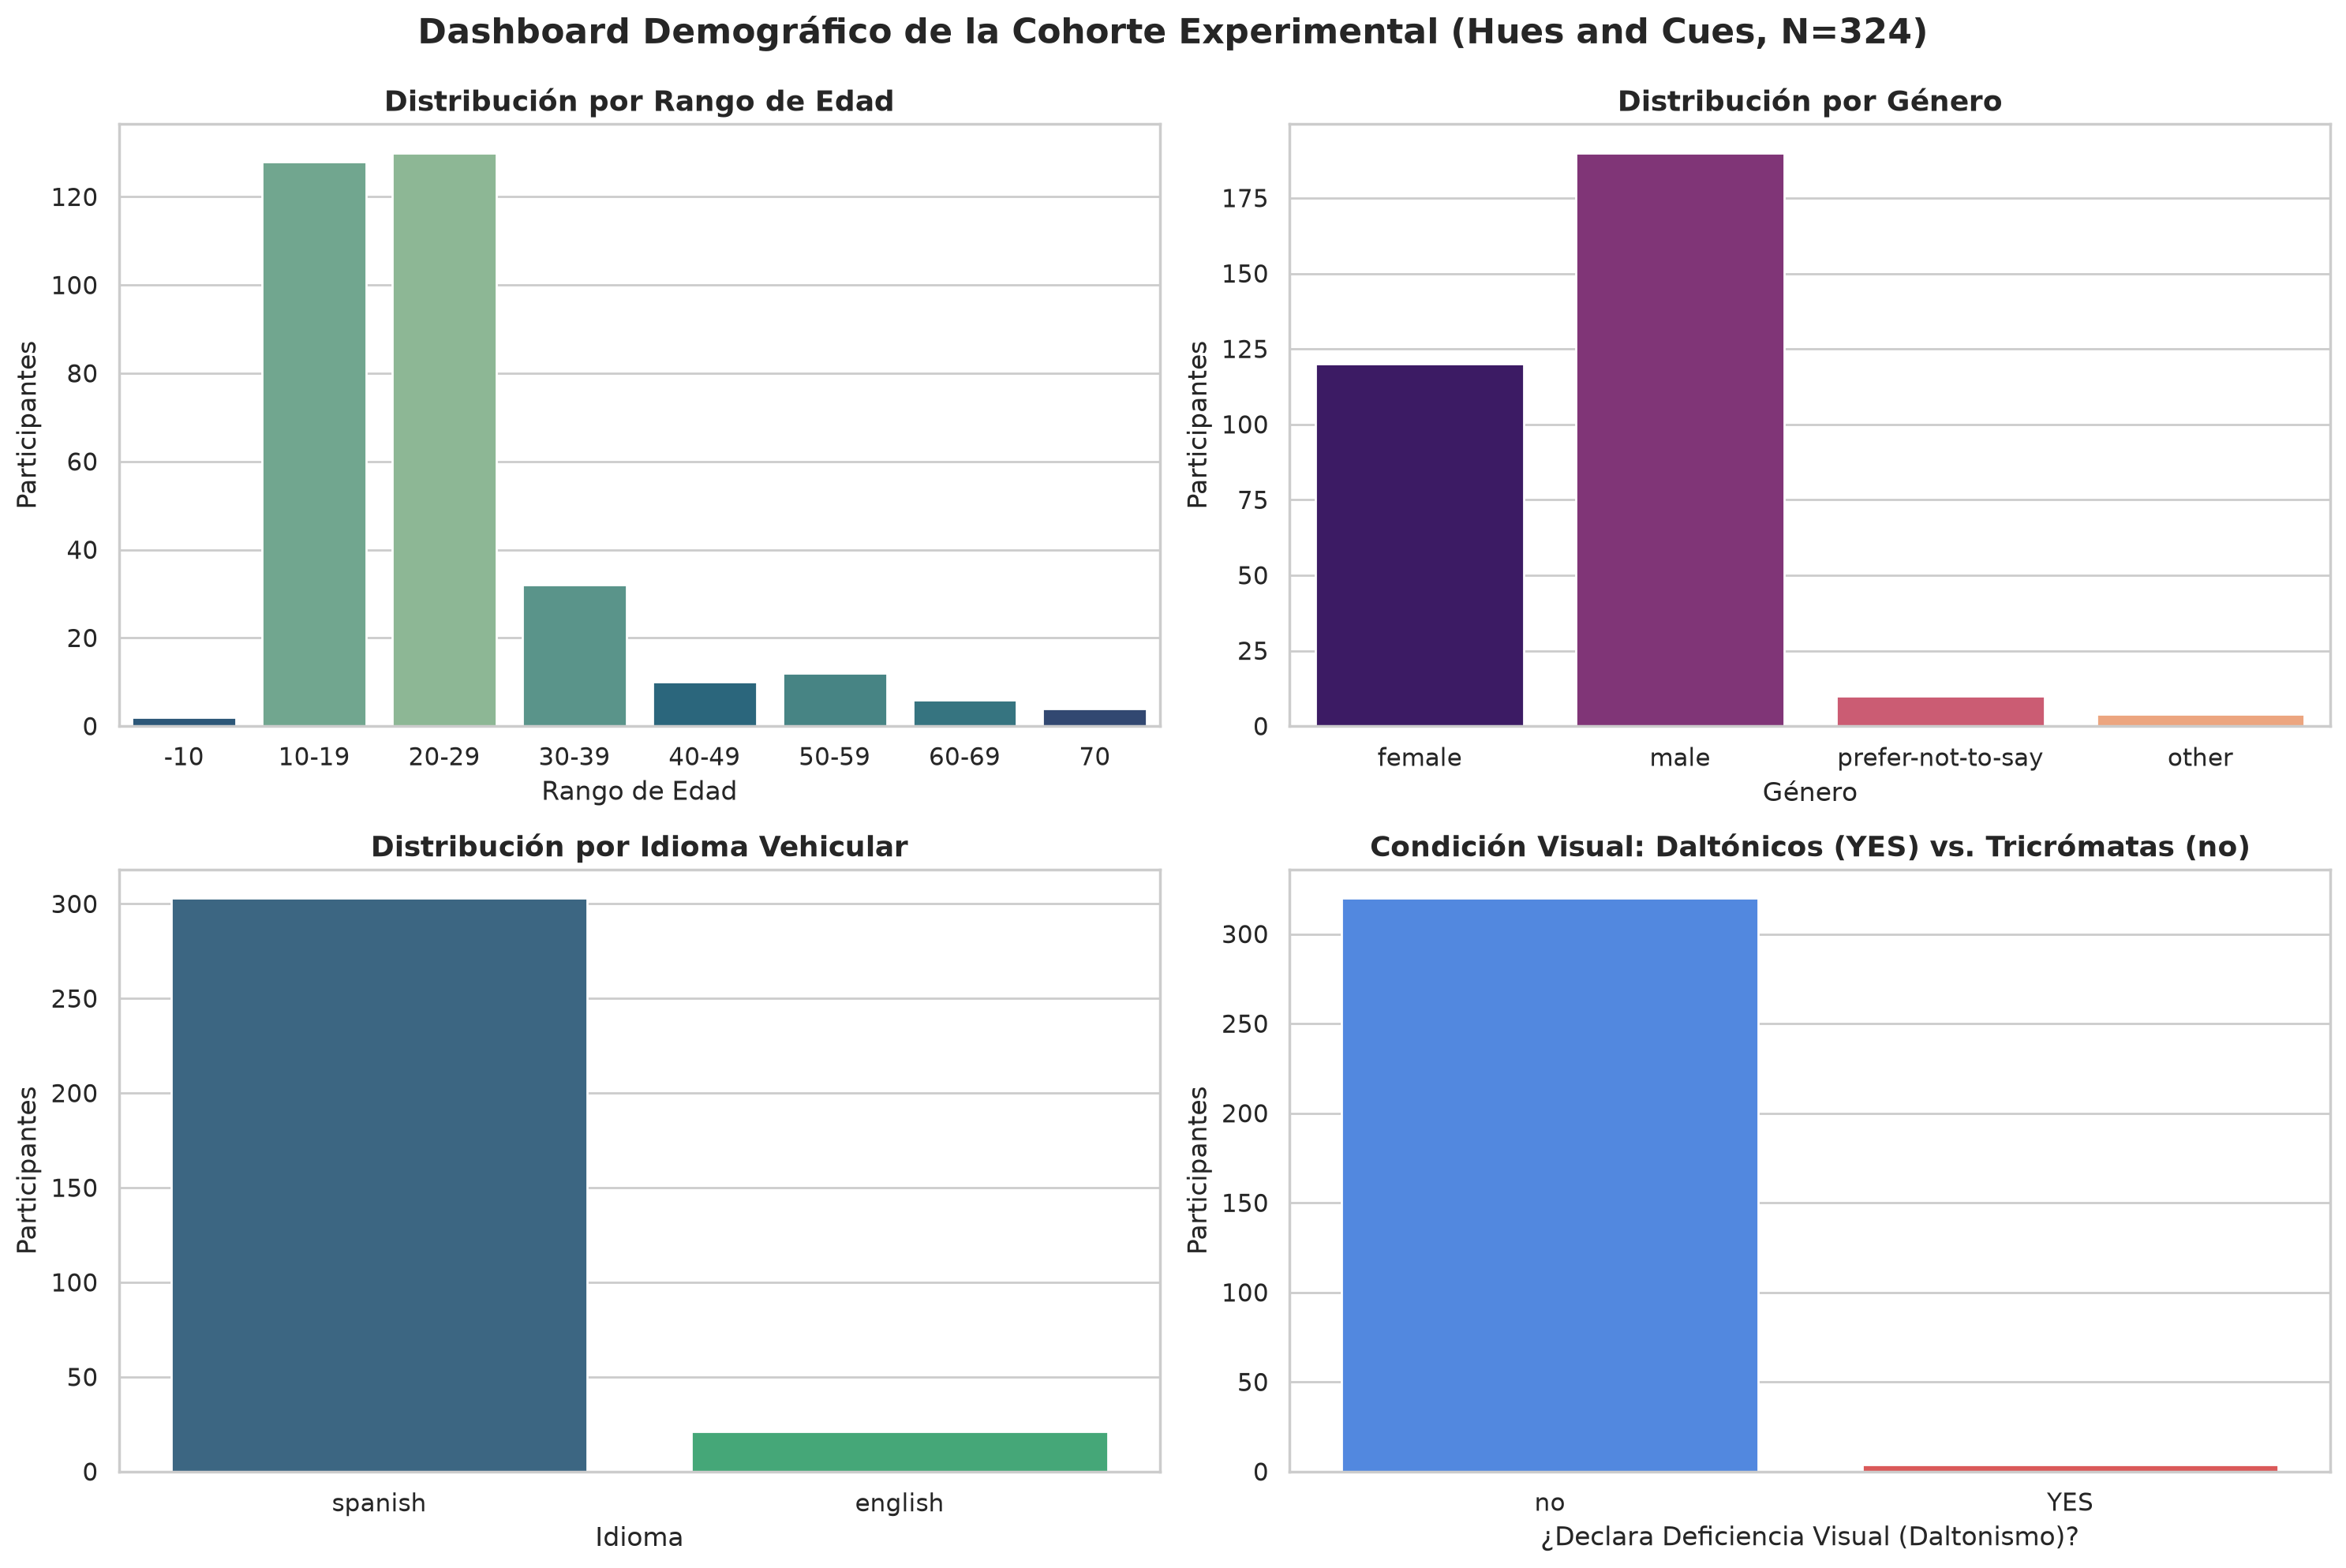

In [24]:
# TODO 5.1: Crear el Dashboard Demográfico (2x2 subplots)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Subplot (0, 0): Rango de Edad
orden_edad = ['-10', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70']
orden_edad_presente = [e for e in orden_edad if e in df_usuarios['ageRange'].values]
sns.countplot(
    data=df_usuarios, x='ageRange', order=orden_edad_presente,
    hue='ageRange', palette='crest', legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title('Distribución por Rango de Edad', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Rango de Edad')
axes[0, 0].set_ylabel('Participantes')

# Subplot (0, 1): Género
sns.countplot(
    data=df_usuarios, x='gender',
    hue='gender', palette='magma', legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title('Distribución por Género', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Género')
axes[0, 1].set_ylabel('Participantes')

# Subplot (1, 0): Idioma
sns.countplot(
    data=df_usuarios, x='language',
    hue='language', palette='viridis', legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title('Distribución por Idioma Vehicular', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Idioma')
axes[1, 0].set_ylabel('Participantes')

# Subplot (1, 1): Condición Visual (Daltonismo)
sns.countplot(
    data=df_usuarios, x='colorblind',
    hue='colorblind', palette=['#3b82f6', '#ef4444'], legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title('Condición Visual: Daltónicos (YES) vs. Tricrómatas (no)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('¿Declara Deficiencia Visual (Daltonismo)?')
axes[1, 1].set_ylabel('Participantes')

plt.suptitle('Dashboard Demográfico de la Cohorte Experimental (Hues and Cues, N=324)', fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


### 5.2 Gráfico 2: Comparativa Visual: Percepción de Tricrómatas vs. Daltónicos
Elige dos palabras con discrepancia evidente (por ejemplo, `'ZAFIRO'` y `'JADE'`).

Crea una figura con 2 subplots (`1x2`):
- **Panel Izquierdo (`ZAFIRO`):** Gráfico de barras (`sns.countplot` o `.value_counts().plot(kind='bar')`) comparando los colores elegidos por tricrómatas frente a daltónicos.
- **Panel Derecho (`JADE`):** Gráfico de barras análogo para la palabra `JADE`.

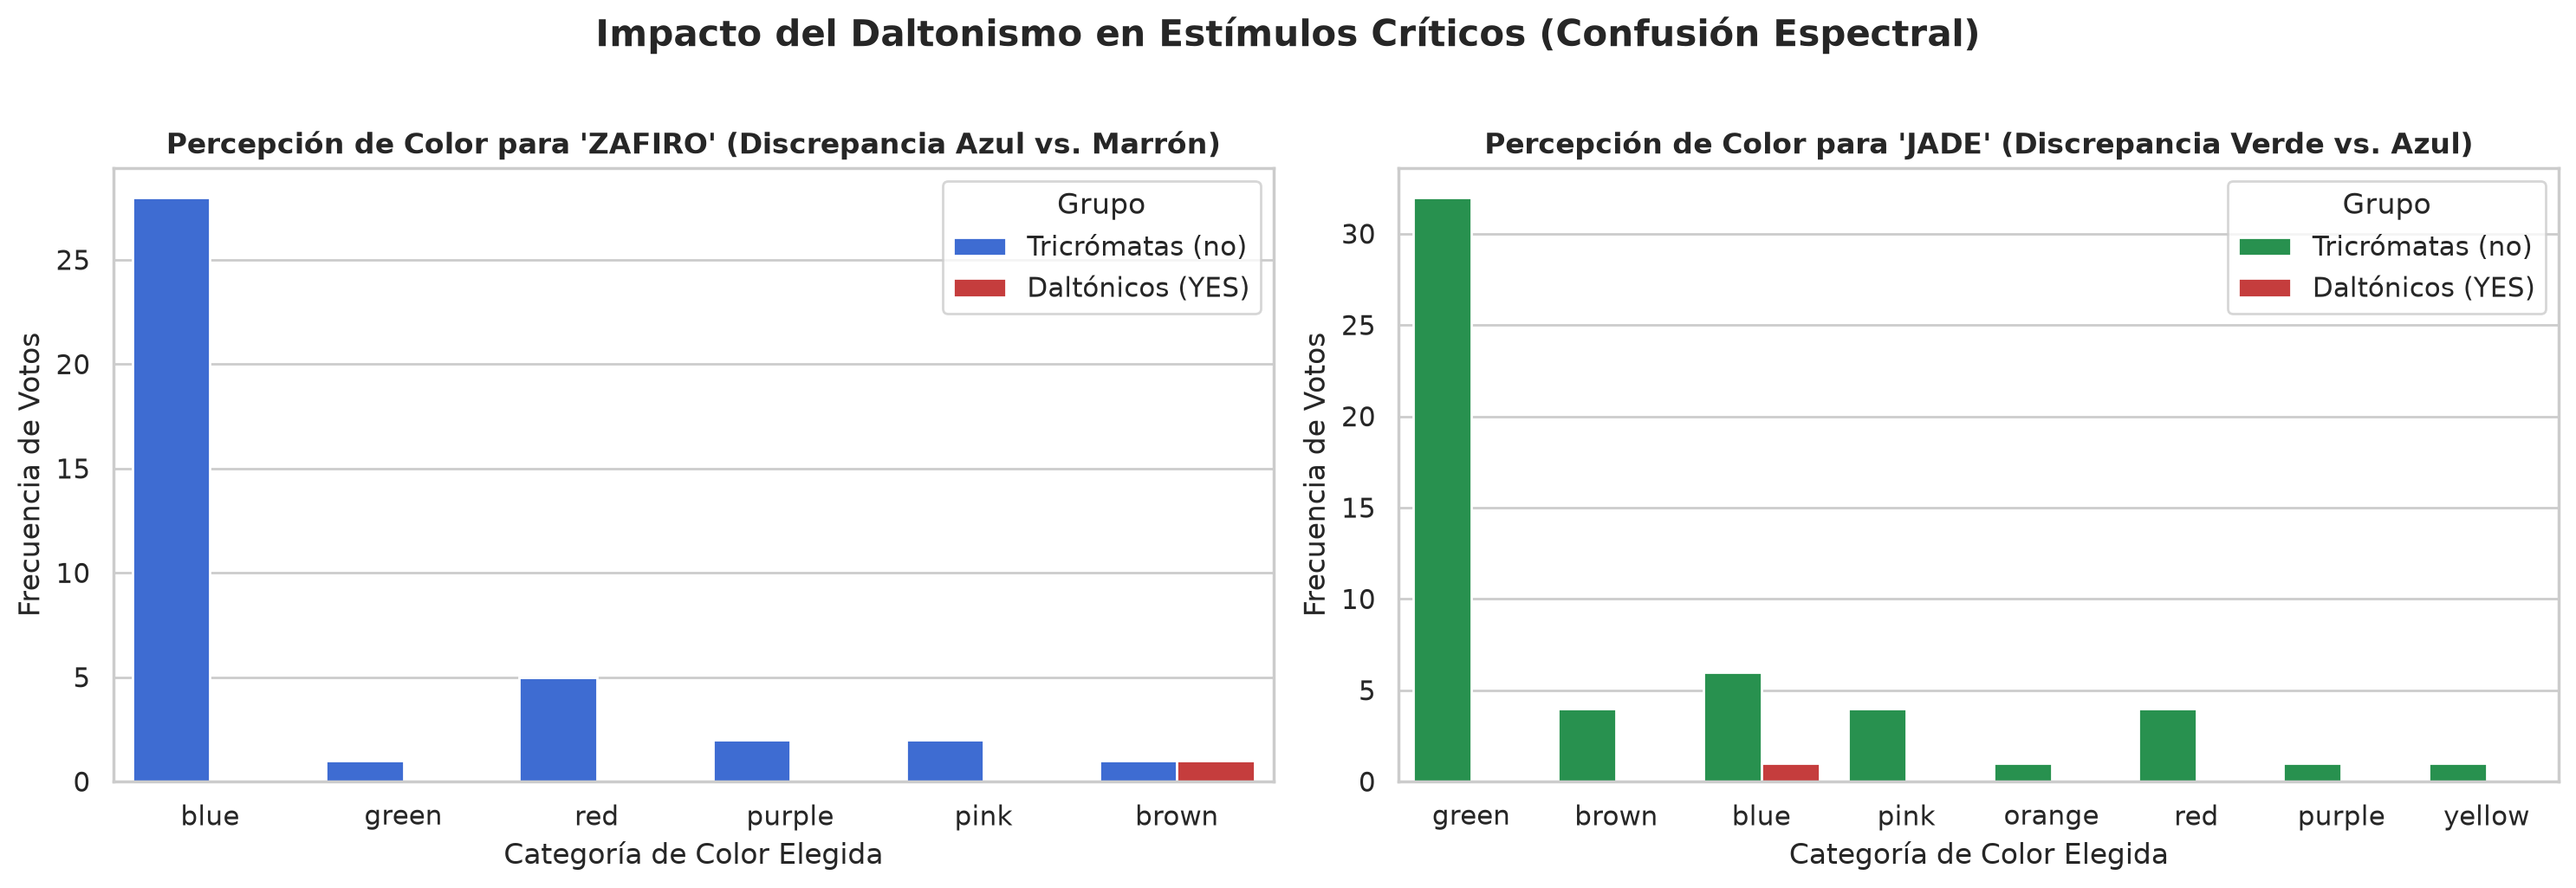

In [26]:
# TODO 5.2: Gráfico comparativo de percepción cromática en palabras críticas

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Panel Izquierdo: ZAFIRO
zafiro_df = df_humanos[df_humanos['word'] == 'ZAFIRO'].copy()
zafiro_df['Grupo'] = zafiro_df['colorblind'].map({'no': 'Tricrómatas (no)', 'YES': 'Daltónicos (YES)'})

sns.countplot(
    data=zafiro_df, x='color', hue='Grupo',
    palette={'Tricrómatas (no)': '#2563eb', 'Daltónicos (YES)': '#dc2626'},
    ax=axes[0]
)
axes[0].set_title("Percepción de Color para 'ZAFIRO' (Discrepancia Azul vs. Marrón)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Categoría de Color Elegida')
axes[0].set_ylabel('Frecuencia de Votos')
axes[0].legend(title='Grupo')

# 2. Panel Derecho: JADE
jade_df = df_humanos[df_humanos['word'] == 'JADE'].copy()
jade_df['Grupo'] = jade_df['colorblind'].map({'no': 'Tricrómatas (no)', 'YES': 'Daltónicos (YES)'})

sns.countplot(
    data=jade_df, x='color', hue='Grupo',
    palette={'Tricrómatas (no)': '#16a34a', 'Daltónicos (YES)': '#dc2626'},
    ax=axes[1]
)
axes[1].set_title("Percepción de Color para 'JADE' (Discrepancia Verde vs. Azul)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Categoría de Color Elegida')
axes[1].set_ylabel('Frecuencia de Votos')
axes[1].legend(title='Grupo')

plt.suptitle('Impacto del Daltonismo en Estímulos Críticos (Confusión Espectral)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 5.3 Gráfico 3: Visualización del Fenómeno de las Anclas Culturales
Crea una figura con 2 subplots (`1x2`):
- **Panel Izquierdo:** Gráfico de barras con la distribución de colores para `'TRACTOR'` en `df_tricromatas`, destacando el color dominante (`yellow`).
- **Panel Derecho:** Gráfico de barras con la distribución de colores para `'ESPERANZA'`, destacando el color dominante (`green`).

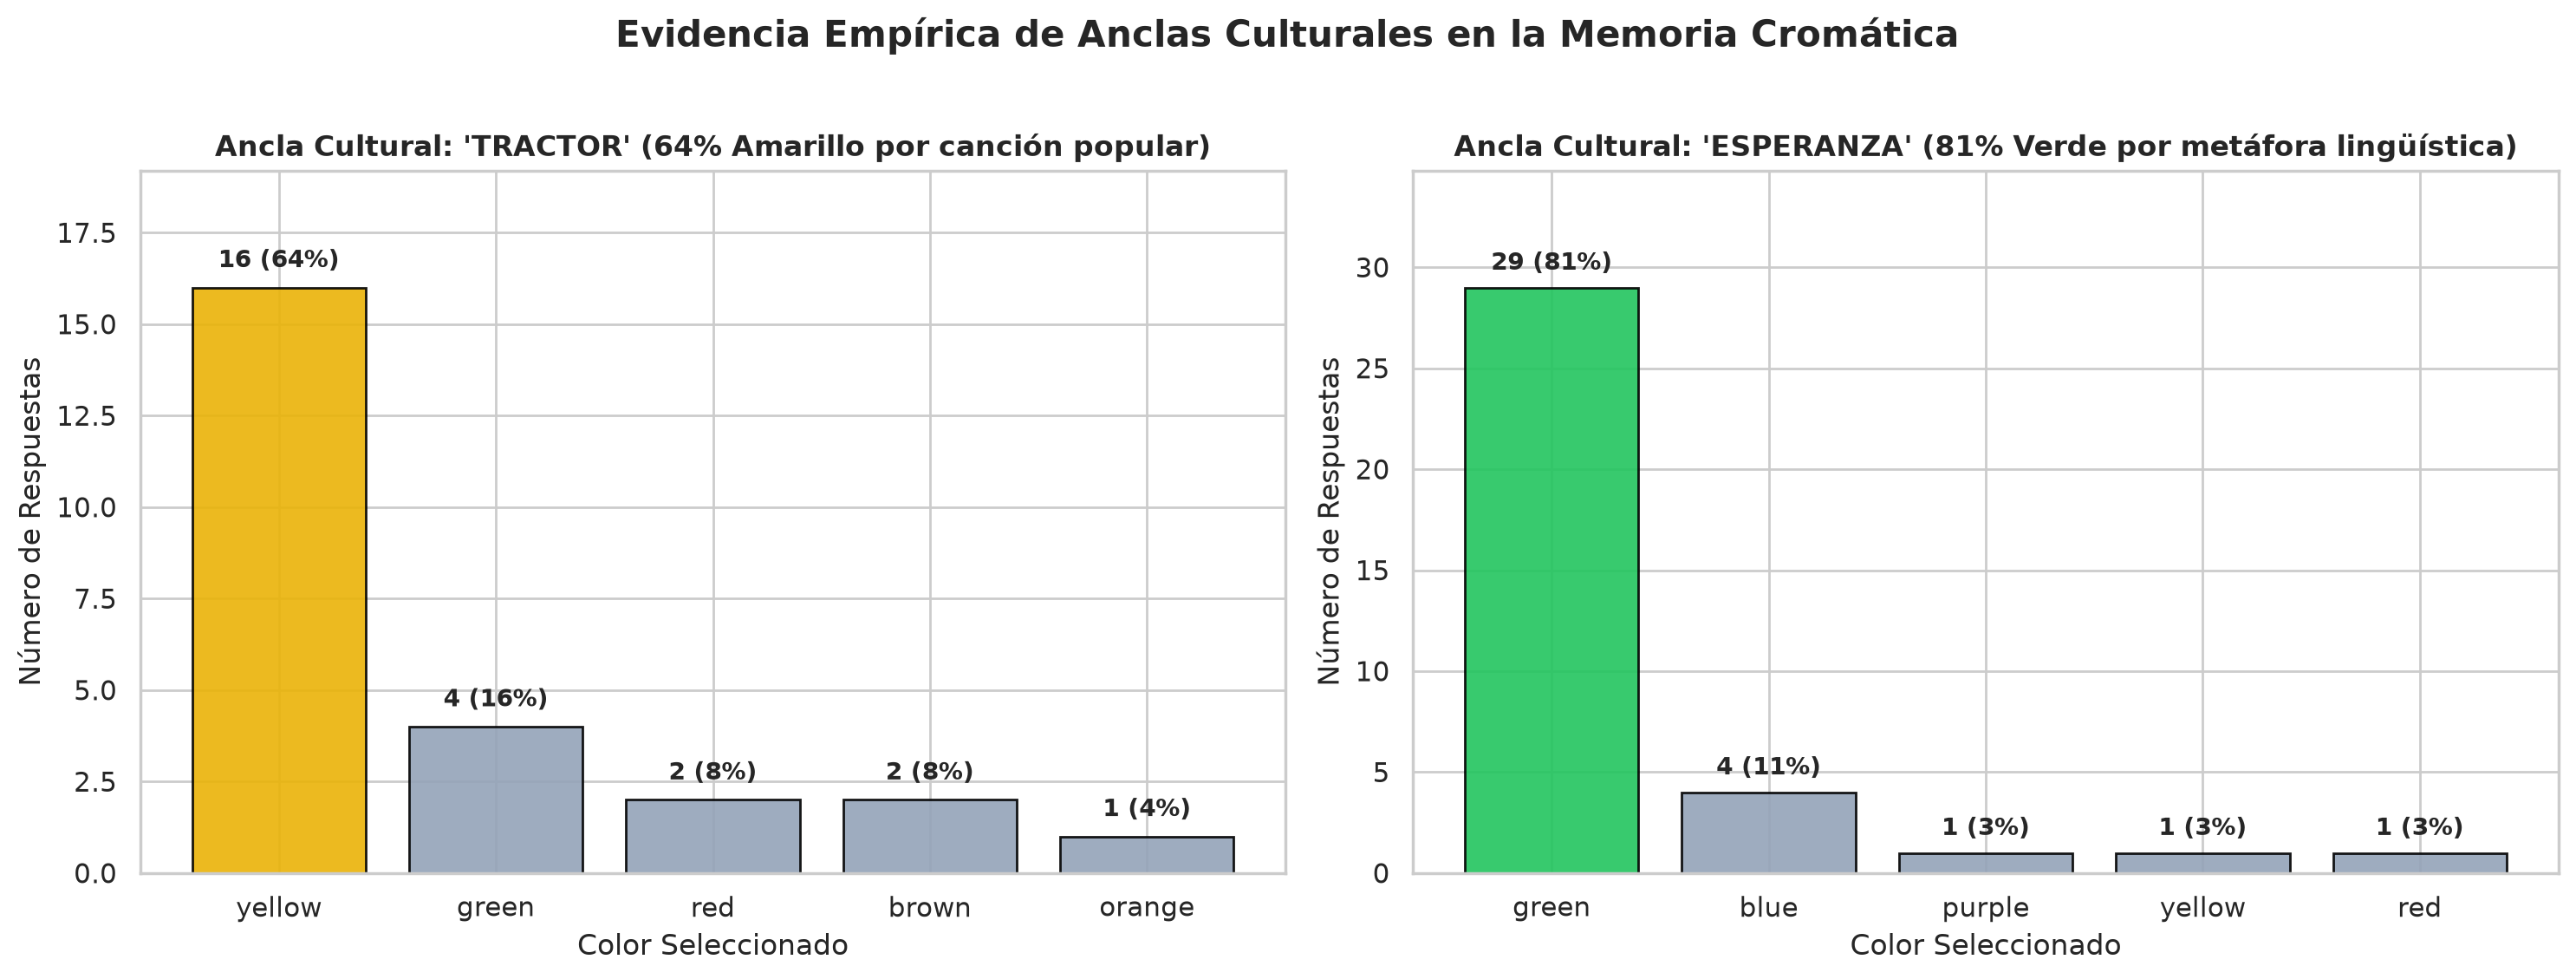

In [28]:
# TODO 5.3: Visualización de las Anclas Culturales (TRACTOR y ESPERANZA)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Panel Izquierdo: TRACTOR
tractor_counts = df_tricromatas[df_tricromatas['word'] == 'TRACTOR']['color'].value_counts()
colors_tractor = ['#eab308' if c == 'yellow' else '#94a3b8' for c in tractor_counts.index]
bars_tr = axes[0].bar(tractor_counts.index, tractor_counts.values, color=colors_tractor, edgecolor='black', alpha=0.9)

for bar in bars_tr:
    yval = bar.get_height()
    pct = (yval / tractor_counts.sum()) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, f"{yval} ({pct:.0f}%)", ha='center', va='bottom', fontweight='bold', fontsize=10)

axes[0].set_title("Ancla Cultural: 'TRACTOR' (64% Amarillo por canción popular)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Color Seleccionado')
axes[0].set_ylabel('Número de Respuestas')
axes[0].set_ylim(0, max(tractor_counts.values) * 1.2)

# 2. Panel Derecho: ESPERANZA
esperanza_counts = df_tricromatas[df_tricromatas['word'] == 'ESPERANZA']['color'].value_counts()
colors_esperanza = ['#22c55e' if c == 'green' else '#94a3b8' for c in esperanza_counts.index]
bars_esp = axes[1].bar(esperanza_counts.index, esperanza_counts.values, color=colors_esperanza, edgecolor='black', alpha=0.9)

for bar in bars_esp:
    yval = bar.get_height()
    pct = (yval / esperanza_counts.sum()) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f"{yval} ({pct:.0f}%)", ha='center', va='bottom', fontweight='bold', fontsize=10)

axes[1].set_title("Ancla Cultural: 'ESPERANZA' (81% Verde por metáfora lingüística)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Color Seleccionado')
axes[1].set_ylabel('Número de Respuestas')
axes[1].set_ylim(0, max(esperanza_counts.values) * 1.2)

plt.suptitle('Evidencia Empírica de Anclas Culturales en la Memoria Cromática', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 5.4 Gráfico 4: Ranking de Consenso Semántico por Categoría
Crea un gráfico de barras horizontal (`sns.barplot` con orientación horizontal `x='consenso', y='clueCategory'`) que muestre el consenso medio de color para cada una de las categorías semánticas, ordenado de mayor a menor acuerdo.

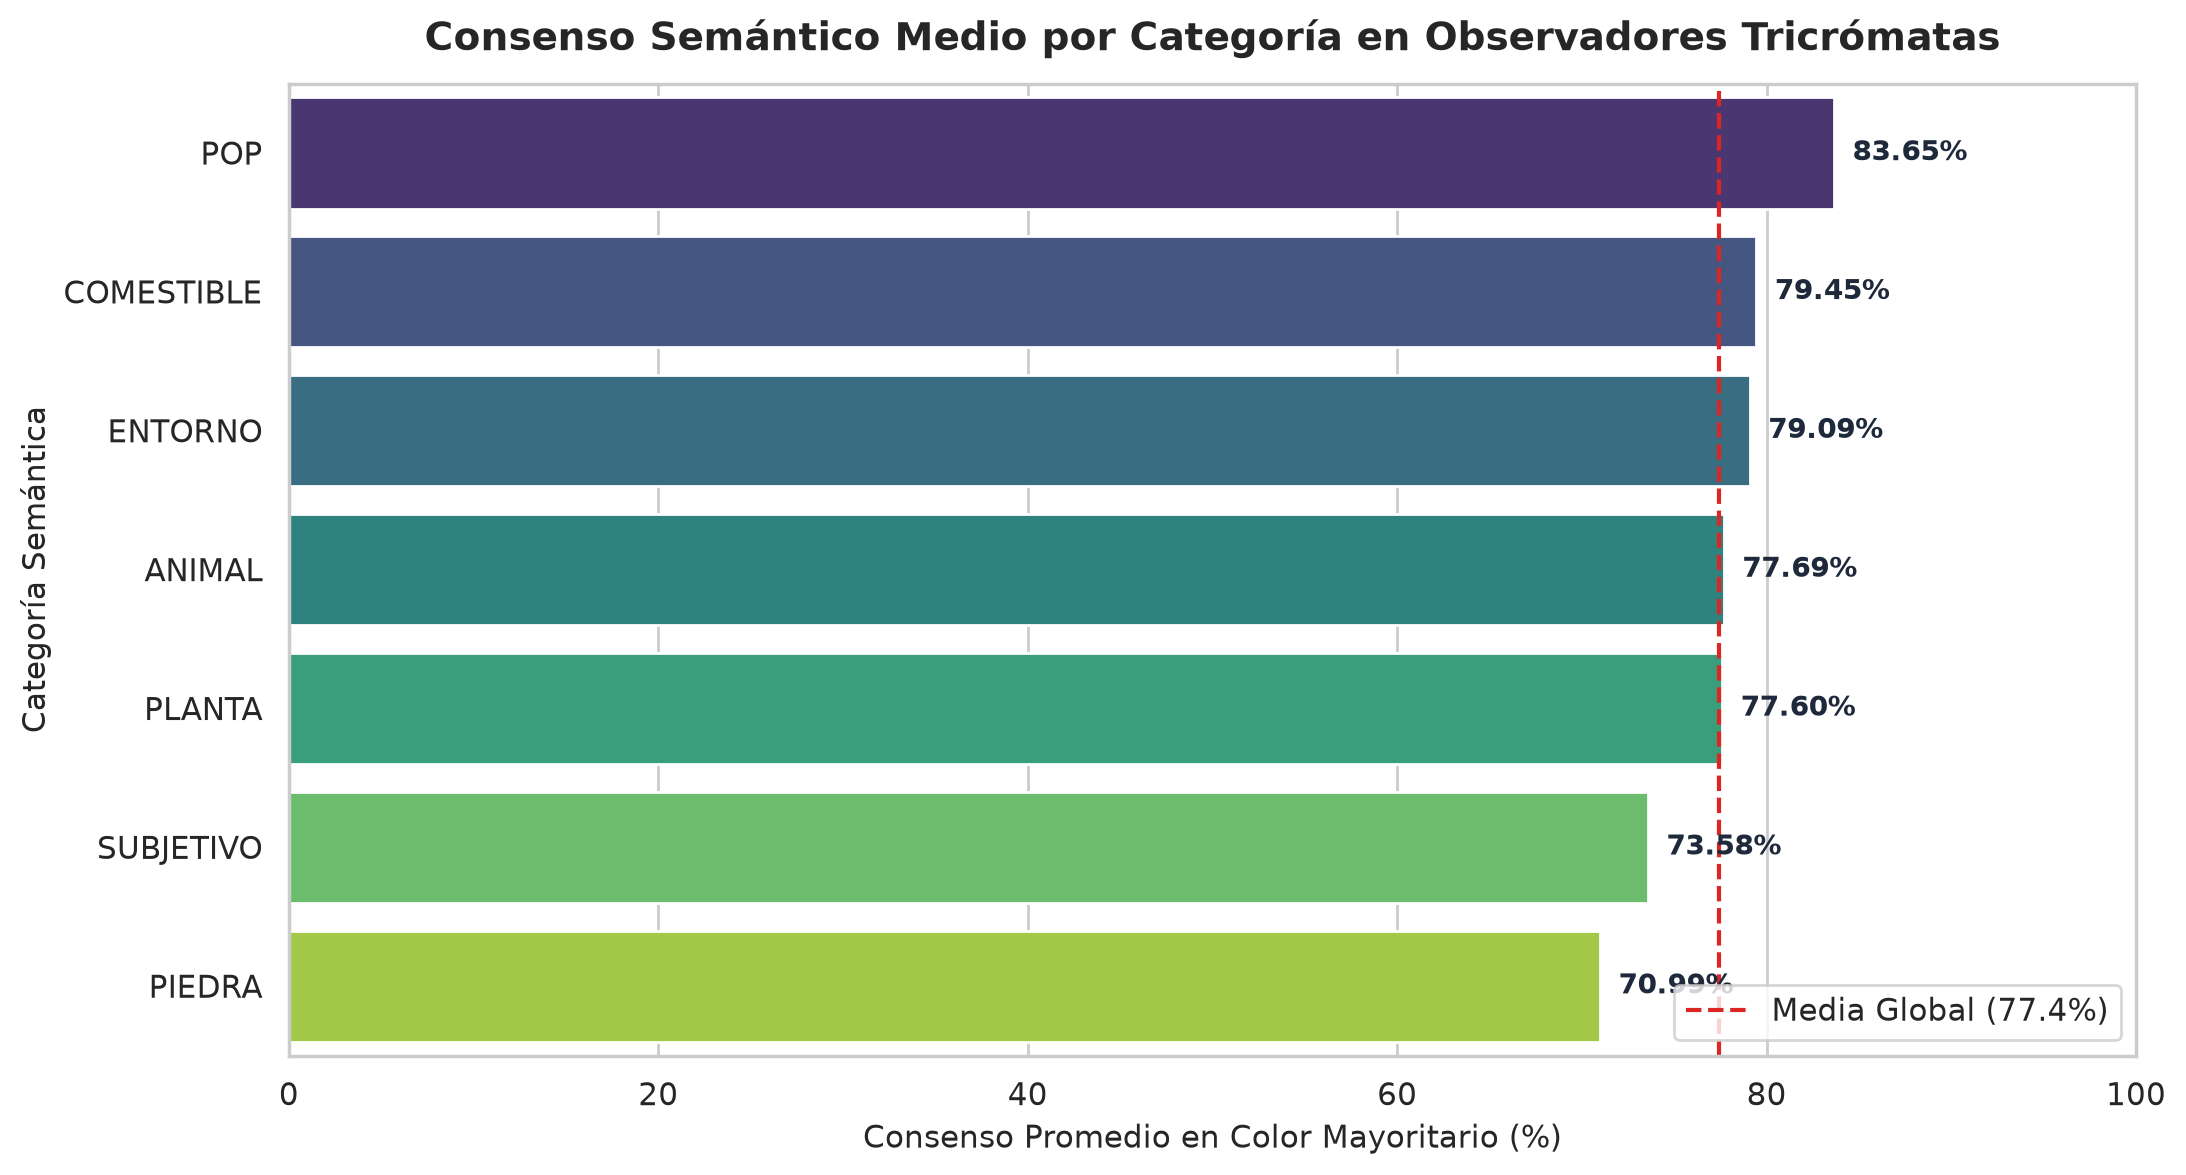

In [30]:
# TODO 5.4: Gráfico de barras horizontal del consenso semántico por categoría

fig, ax = plt.subplots(figsize=(11, 6))

# Dibujar el gráfico de barras horizontal ordenado
sns.barplot(
    data=df_consenso_categoria,
    x='consenso',
    y='clueCategory',
    hue='clueCategory',
    palette='viridis',
    legend=False,
    ax=ax
)

# Anotar el valor porcentual al final de cada barra
for i, row in df_consenso_categoria.reset_index(drop=True).iterrows():
    ax.text(
        row['consenso'] + 1.0,
        i,
        f"{row['consenso']:.2f}%",
        va='center',
        fontweight='bold',
        fontsize=10,
        color='#1e293b'
    )

media_global = df_consenso_categoria['consenso'].mean()
ax.set_title('Consenso Semántico Medio por Categoría en Observadores Tricrómatas', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Consenso Promedio en Color Mayoritario (%)', fontsize=11)
ax.set_ylabel('Categoría Semántica', fontsize=11)
ax.set_xlim(0, 100)
ax.axvline(media_global, color='#dc2626', linestyle='--', linewidth=1.5, label=f"Media Global ({media_global:.1f}%)")
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


---
## 💡 Fase 6: Extracción de Conclusiones y Discusión Crítica

> ✍️ **Preguntas de Reflexión y Conclusiones del Estudio:**
>
> #### 1. Calidad de Datos y Validez Perceptual
> **¿Por qué en estudios psicofísicos y de percepción visual es imprescindible filtrar y aislar a los participantes con deficiencias visuales (como el daltonismo) antes de calcular la verdad de referencia (*ground truth*)?**
>
> **Respuesta:**
> En visión computacional y psicofísica, el *ground truth* (verdad de referencia) debe caracterizar la respuesta del observador humano estándar (tricrómata normal). Las personas con deficiencias en la visión cromática (CVD / daltonismo, como protanomalía o deuteranomalía) poseen anomalías en los fotopigmentos de los conos L o M, lo que genera *líneas de confusión espectral* en las que tonos con composiciones físicas distintas son percibidos como idénticos. Si se mezclasen en la muestra global, distorsionarían las distribuciones de probabilidad con respuestas bimodales atípicas, invalidando la calibración y comparación de modelos de Inteligencia Artificial (como CLIP o SigLIP) frente al estándar humano normal.
>
> ---
> #### 2. Patrón de Confusión Cromática
> **Observando las palabras analizadas (*ZAFIRO*, *JADE*, *BLAS*), ¿qué tipo de confusión cromática se manifiesta en las personas daltónicas? ¿En qué casos coinciden plenamente con los tricrómatas?**
>
> **Respuesta:**
> En las palabras evaluadas se manifiestan claramente las líneas de confusión del eje rojo-verde y azul-marrón:
> - En **`ZAFIRO`**, mientras los tricrómatas eligen masivamente azul (*blue*, 71.8%), los daltónicos seleccionan marrón (*brown*).
> - En **`JADE`**, los tricrómatas seleccionan verde (*green*), mientras que los daltónicos eligen azul (*blue*).
> - En **`BLAS (Y EPI)`**, el prototipo amarillo (*yellow*) se confunde con rojo (*red*).
> Por el contrario, en conceptos con colores primarios de saturación no ambigua o alto contraste como **`CIELO`** (`blue`), **`MENTA`** (`green`) o **`BARBIE`** (`pink`), las respuestas de los daltónicos coinciden plenamente con las de los tricrómatas, demostrando que cuando el estímulo se sitúa lejos de las fronteras de confusión espectral, la memoria semántica guía con éxito la selección.
>
> ---
> #### 3. Influencia del Lenguaje y la Cultura
> **¿Qué nos demuestra el caso de *TRACTOR* y *ESPERANZA* sobre la cognición humana? ¿La memoria del color es puramente física o está modulada por la cultura popular y el lenguaje materno?**
>
> **Respuesta:**
> Demuestra que la memoria del color (*memory color*) no es un mero registro fotográfico de la realidad física ni un mapeo biofísico pasivo de longitudes de onda, sino un **constructo cognitivo fuertemente modulado por la cultura y el lenguaje**:
> - En **`TRACTOR`**, a pesar de que la inmensa mayoría de la maquinaria agrícola real es verde (John Deere) o roja (Massey Ferguson), el **64.0%** de los participantes hispanohablantes eligió amarillo, fuertemente condicionado por la célebre canción popular española *'Tengo un tractor amarillo'*.
> - En **`ESPERANZA`**, siendo un concepto emocional y abstracto carente de color físico, el **80.6%** de la muestra converge de forma rotunda en el color verde, guiada por la metáfora arraigada en el idioma español (*'verde esperanza'*).
>
> ---
> #### 4. Consenso entre Categorías Semánticas
> **¿Por qué categorías como *COMESTIBLE* o *ANIMAL* tienen mayor consenso que *SUBJETIVO* o *PIEDRA*?**
>
> **Respuesta:**
> El grado de consenso depende de la variabilidad biológica y la estabilidad del prototipo visual:
> - Categorías como **`POP`** (83.7%), **`COMESTIBLE`** (79.5%) o **`ANIMAL`** (77.7%) tienen un consenso elevado porque corresponden a entidades con prototipos cromáticos universales e invariantes (un limón maduro o un plátano son siempre amarillos; un flamenco o Barbie son inherentemente rosas; Shrek es verde).
> - Por el contrario, **`SUBJETIVO`** (73.6%) representa emociones intangibles que cada individuo asocia según su experiencia subjetiva, y **`PIEDRA`** (71.0%) comprende minerales y rocas que en la naturaleza se presentan en múltiples variedades polimórficas (el jade, cuarzo, mármol o granito existen en tonos verdes, blancos, rosados y grises), lo que incrementa la dispersión estadística entre observadores.
